In [23]:
import pandas as pd

df = pd.read_csv("data/wti_hmm_features.csv", parse_dates=["date"])

In [24]:
df.describe()

,date,r_t,sigma20,TS,OVX
count,4156,4156.000000,4156.000000,4156.000000,4156.000000
mean,2015-11-19 03:31:00.635226,0.000078,0.374659,-0.012586,38.695842
min,2007-06-08 00:00:00,-0.720273,0.104240,-0.769572,14.500000
25%,2011-09-26 18:00:00,-0.012335,0.233624,-0.022958,29.320000
50%,2015-12-05 12:00:00,0.000824,0.301348,-0.008136,35.395000
75%,2020-02-11 06:00:00,0.013037,0.412752,0.013297,44.045000
max,2024-04-05 00:00:00,0.425832,3.773373,0.125248,325.150000
std,NaN,0.031018,0.322952,0.052214,17.552420


In [25]:
df = df.sort_values("date")
df = df.set_index("date")
df.head()

,r_t,sigma20,TS,OVX
date,,,,
2007-06-08,-0.032650,0.269816,-0.033407,26.51
2007-06-11,0.017597,0.274593,-0.032804,25.99
2007-06-12,-0.008683,0.277582,-0.034886,25.81
2007-06-13,0.012317,0.278671,-0.033393,26.07
2007-06-14,0.021677,0.283132,-0.026979,26.35


In [26]:
print(df.index.min())
print(df.index.max())

2007-06-08 00:00:00
2024-04-05 00:00:00


In [28]:
print(raw.shape)
print(raw.notna().sum())

(5070, 4)
WTI_SPOT    4816
OVX         4891
F1          4256
F4          4255
dtype: int64


In [31]:
import pandas as pd

df = pd.read_csv(
    "data/wti_hmm_features.csv",
    parse_dates=["date"],
    index_col="date"
)

df = df.sort_index()

In [32]:
def get_rolling_window(df, end_date, years=5):

    end_date = pd.Timestamp(end_date)
    start_date = end_date - pd.DateOffset(years=years)

    window = df.loc[start_date:end_date].copy()

    return window

In [34]:
from sklearn.preprocessing import StandardScaler

def standardize_window(window):
    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(window)

    X_scaled = pd.DataFrame(
        X_scaled,
        index=window.index,
        columns=window.columns
    )

    return X_scaled, scaler

In [65]:
window = get_rolling_window(
    df,
    end_date="2015-01-01",
    years=10
)

X_scaled, scaler = standardize_window(window)

In [66]:
from hmmlearn.hmm import GaussianHMM
import pandas as pd

In [77]:
model = GaussianHMM(
    n_components=3,
    covariance_type="full",
    n_iter=500,
    tol=1e-4,
    random_state=42
)

model.fit(X_scaled.values)

,n_components,3
,covariance_type,'full'
,random_state,42
,n_iter,500
,tol,0.0001
,min_covar,0.001
,startprob_prior,1.0
,transmat_prior,1.0
,means_prior,0
,means_weight,0
,covars_prior,0.01


In [78]:
print("Converged:", model.monitor_.converged)
print("Iterations:", model.monitor_.iter)
print("Log-likelihood:", model.score(X_scaled.values))

Converged: True
Iterations: 110
Log-likelihood: -5121.1531357438025


In [79]:
states = model.predict(X_scaled.values)

In [80]:
regime_means = pd.DataFrame(
    scaler.inverse_transform(model.means_),
    columns=window.columns,
    index=[f"state_{k}" for k in range(3)]
)

regime_means

,r_t,sigma20,TS,OVX
state_0,0.000328,0.209612,-0.007342,26.725073
state_1,-0.000028,0.344355,-0.004604,38.504237
state_2,-0.003085,0.826742,-0.097549,69.685377


In [81]:
transitions = pd.DataFrame(
    model.transmat_,
    index=["state_0", "state_1", "state_2"],
    columns=["state_0", "state_1", "state_2"]
)

transitions

,state_0,state_1,state_2
state_0,0.987455,0.010243,0.002302
state_1,0.012186,0.986569,0.001245
state_2,0.005403,0.011956,0.982641


In [82]:
result = window.copy()
result["state"] = states
result["state"].value_counts(normalize=True).sort_index()


state
0    0.468177
1    0.438511
2    0.093312
Name: proportion, dtype: float64

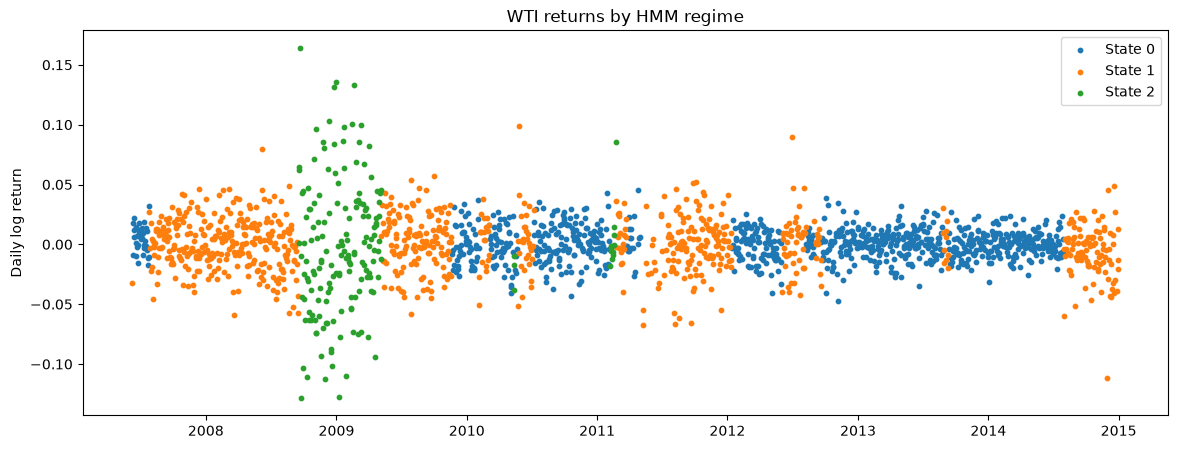

In [84]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

for state in range(3):
    mask = result["state"] == state

    ax.scatter(
        result.index[mask],
        result.loc[mask, "r_t"],
        s=10,
        label=f"State {state}"
    )

ax.legend()
ax.set_title("WTI returns by HMM regime")
ax.set_ylabel("Daily log return")

plt.show()